<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/04_Ml_y_Validacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **4 - Machine Learning y Validación**

In [ ]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [ ]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold,
    cross_val_score,
    StratifiedGroupKFold
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    MinMaxScaler,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
# Usaremos estas distribuciones para samplear en el RandomSearchCV
from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

In [ ]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "datos" / "procesados"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_filtrado.csv")
df_muestra = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_muestra.csv")

In [33]:
TARGET = "log_daily_price"

X, y = df.drop(columns=TARGET), df[TARGET]
X_muestra, y_muestra = df_muestra.drop(columns=TARGET), df_muestra[TARGET]

In [7]:
X.columns, len(X.columns)

(Index(['host_is_superhost', 'host_total_listings_count',
        'neighbourhood_cleansed', 'latitude', 'longitude', 'accommodates',
        'bathrooms', 'bedrooms', 'guests_included', 'minimum_nights',
        'availability_365', 'number_of_reviews', 'review_scores_rating', 'TV',
        'WiFi', 'Air_Condition', 'Breakfast', 'Elevator', 'Washer', 'Iron',
        'Host_greets_you', 'Paid_parking_on_premises',
        'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
        'Pets_allowed', 'Smoking_allowed', 'check_in_24_hour'],
       dtype='str'),
 28)

Separamos los features en sus respectivas categorias para poder usar un pipeline.


In [31]:
# 1. Variables numéricas
numeric_features = [
    "host_total_listings_count",
    "latitude",
    "longitude",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "guests_included",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "review_scores_rating"
]

# 2. Variables categóricas nominales
categorical_features = ["neighbourhood_cleansed"]

# 3. Variables binarias
binary_features = [
    "host_is_superhost",
    "TV",
    "WiFi",
    "Air_Condition",
    "Breakfast",
    "Elevator",
    "Washer",
    "Iron",
    "Host_greets_you",
    "Paid_parking_on_premises",
    "Luggage_dropoff_allowed",
    "Long_term_stays_allowed",
    "Doorman",
    "Pets_allowed",
    "Smoking_allowed",
    "check_in_24_hour"
]

## 1. Dividimos en train y test

In [41]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# X_train_muestra, X_test_muestra, y_train_muestra, y_test_muestra = train_test_split(
#     X_muestra, y_muestra, test_size=TEST_SIZE, random_state=RANDOM_STATE
# )

print(f"Total de registros en la base: {df.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train.shape[1]}")


# print("\n============== MUESTRA ==============")
# print(f"Total de registros en la base: {df_muestra.shape[0]}")
# print(f"Registros para ENTRENAR los modelos (X_train): {X_train_muestra.shape[0]}")
# print(f"Registros para TESTEAR los modelos (X_test): {X_test_muestra.shape[0]}")
# print(f"Cantidad de variables predictoras: {X_train_muestra.shape[1]}")

Total de registros en la base: 9297
Registros para ENTRENAR los modelos (X_train): 7437
Registros para TESTEAR los modelos (X_test): 1860
Cantidad de variables predictoras: 28


## 2. Implementación de Algoritmos:

Para el entrenamiento y comparación de modelos se seleccionaron tres algoritmos: Random Forest, Gradient Boosting y k-Nearest Neighbors (k-NN).
La elección buscó representar distintos enfoques de aprendizaje supervisado vistos en clase

- **Random Forest Regressor**: como representante de los métodos basados en árboles de decisión y técnicas de bagging, ya que combina múltiples árboles para reducir la varianza y mejorar la capacidad de generalización.
- **Gradient Boosting**: como representante de los métodos de boosting, que construyen árboles de manera secuencial, buscando corregir los errores de las predicciones anteriores.
- **k-NN** como un enfoque alternativo, más simple y conceptualmente diferente de los anteriores, dado que realiza predicciones a partir de la proximidad entre observaciones, sin construir un conjunto de árboles.

En una primera etapa, entrenaremos los tres algoritmos seleccionados (Random Forest, Gradient Boosting y KNN) utilizando sus hiperparámetros por defecto, con el objetivo de establecer un piso que permita comparar sus desempeños antes de realizar cualquier optimización.

In [98]:
# 1. Random Forest Regressor
reg_rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Gradient Boosting Regressor
reg_gb = GradientBoostingRegressor(
    random_state=RANDOM_STATE
)

# Preprocesador/Transofrmador para el entrenamiento del Random Forest y Gradient Boosting
preprocessor_trees = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

pipeline_gb = Pipeline([
    ("preprocessor", preprocessor_trees),
    ("regressor", reg_gb)
])

pipeline_rf = Pipeline([
    ("preprocessor", preprocessor_trees),
    ("regressor", reg_rf)
])

# 3. k-Nearest Neighbors Regressor
reg_knn = KNeighborsRegressor(
    n_jobs=-1
)

# KNN
preprocessor_knn = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

pipeline_knn = Pipeline([
    ("preprocessor", preprocessor_knn),
    ("regressor", reg_knn)
])

## **3. Evaluación de Métricas:**
Sobre los conjuntos de entrenamiento (train) y prueba (test), se calculemos las métricas MAE, MSE, RMSE y R² sobre ambos conjuntos. Esta comparación permitirá identificar posibles indicios de sobreajuste (overfitting), observando las diferencias entre el rendimiento en entrenamiento y en datos no vistos.

In [91]:
def entrenar_y_evaluar(modelo, X_train, y_train, X_test, y_test):
    # Entrenamos el modelo
    modelo.fit(X_train, y_train)

    # Generamos las predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Calculamos las métricas
    metricas = {
        "Train": {
            "MAE": mean_absolute_error(y_train, pred_train),
            "MSE": mean_squared_error(y_train, pred_train),
            "RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
            "R2": r2_score(y_train, pred_train)
        },
        "Test": {
            "MAE": mean_absolute_error(y_test, pred_test),
            "MSE": mean_squared_error(y_test, pred_test),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
            "R2": r2_score(y_test, pred_test)
        }
    }

    return pd.DataFrame(metricas).T

In [92]:
modelos_default = {
    "RandomForest": pipeline_rf,
    "GradientBoosting": pipeline_gb,
    "KNN": pipeline_knn
}

resultados_default = {}

for nombre, modelo in modelos_default.items():
    resultados_default[nombre] = entrenar_y_evaluar(
        modelo,
        X_train,
        y_train,
        X_test,
        y_test
    )

    print(f"\n{'='*15} {nombre} {'='*15}")
    display(resultados_default[nombre].round(4))


=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Train,0.1048,0.0228,0.1511,0.9253
Test,0.2718,0.1554,0.3942,0.4758



=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Train,0.2617,0.1391,0.3730,0.5453
Test,0.2667,0.1504,0.3879,0.4926



=============== KNN ===============


,MAE,MSE,RMSE,R2
Train,0.2560,0.1297,0.3602,0.5761
Test,0.3145,0.1960,0.4428,0.3388


In [93]:
df_default = pd.concat(
    resultados_default,
    names=["Modelo", "Conjunto"]
)

display(df_default.round(4))

MAE     MSE    RMSE      R2
Modelo           Conjunto                                
RandomForest     Train     0.1048  0.0228  0.1511  0.9253
                 Test      0.2718  0.1554  0.3942  0.4758
GradientBoosting Train     0.2617  0.1391  0.3730  0.5453
                 Test      0.2667  0.1504  0.3879  0.4926
KNN              Train     0.2560  0.1297  0.3602  0.5761
                 Test      0.3145  0.1960  0.4428  0.3388

Conjunto,Modelo,R² Train,R² Test,Diferencia
0,RandomForest,0.9253,0.4758,0.4496
1,GradientBoosting,0.5453,0.4926,0.0526
2,KNN,0.5761,0.3388,0.2372


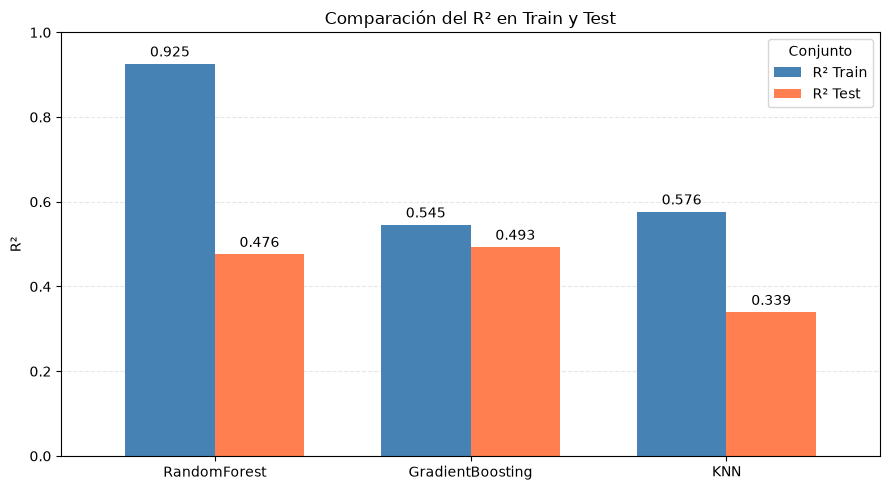

In [94]:
import matplotlib.pyplot as plt

# Extraemos el R² de Train y Test para cada modelo
df_r2 = (
    df_default["R2"]
    .unstack("Conjunto")
    [["Train", "Test"]]
    .rename(columns={
        "Train": "R² Train",
        "Test": "R² Test"
    })
    .reset_index()
)

# Calculamos la diferencia entre Train y Test
df_r2["Diferencia"] = df_r2["R² Train"] - df_r2["R² Test"]

# Mostramos la tabla
display(df_r2.round(4))

# Gráfico
ax = df_r2.plot(
    x="Modelo",
    y=["R² Train", "R² Test"],
    kind="bar",
    figsize=(9, 5),
    rot=0,
    width=0.7,
    color=["steelblue", "coral"]
)

ax.set_title("Comparación del R² en Train y Test")
ax.set_xlabel("")
ax.set_ylabel("R²")
ax.set_ylim(0, 1)
ax.legend(title="Conjunto")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Mostrar valores sobre las barras
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### Análisis de sobreajuste y capacidad de generalización

A partir de la comparación del R² entre los conjuntos de entrenamiento y prueba, se observaron diferencias importantes en la capacidad de generalización de los modelos.

**Random Forest** presentó un sobreajuste considerable, con una diferencia aproximada de 0.449 entre ambos conjuntos (0.925 en train frente a 0.476 en test). Por su parte, **KNN** mostró un sobreajuste moderado, con una diferencia de 0.237 y el peor rendimiento predictivo en test (R² = 0.339).

En cambio, **Gradient Boosting** presentó el comportamiento más equilibrado, con una diferencia de apenas 0.052 entre entrenamiento y prueba (0.545 frente a 0.493). Esto sugiere una buena capacidad de generalización, sin evidencias importantes de sobreajuste. Además, obtuvo el mayor R² en test, aunque con una diferencia relativamente pequeña respecto de Random Forest.

Por estos motivos, **Gradient Boosting se destacó como el mejor modelo inicial**, al combinar el mejor desempeño predictivo en test con la menor brecha entre entrenamiento y prueba. En la siguiente etapa, se aplicarán técnicas de validación cruzada y optimización de hiperparámetros para intentar mejorar el rendimiento de los tres modelos y reducir el sobreajuste observado, especialmente en Random Forest y KNN.

## 4. Optimización
Con el objetivo de mejorar el desempeño predictivo y reducir el sobreajuste observado en algunos modelos, se realizaremos una búsqueda de hiperparámetros mediante RandomizedSearchCV, utilizando validación cruzada de 5 folds sobre el conjunto de entrenamiento.

Posteriormente, se compararán los resultados obtenidos con los modelos iniciales para evaluar si la optimización permitió mejorar su capacidad de generalización.

In [78]:
models_and_params = {
    'RandomForest': {
        'model': RandomForestRegressor(random_state=RANDOM_STATE),
        'preprocessor': preprocessor_trees,
        'params': {
            'regressor__n_estimators': randint(100, 600),
            'regressor__max_depth': randint(3, 25),
            'regressor__min_samples_split': randint(2, 20),
            'regressor__min_samples_leaf': randint(1, 15),
            'regressor__max_features': ['sqrt', 'log2', 0.5, 0.75, 1.0],
            'regressor__max_leaf_nodes': [None, 20, 50, 100, 200],
            'regressor__max_samples': [None, 0.6, 0.8, 1.0],
            'regressor__ccp_alpha': [0.0, 0.0001, 0.001, 0.01],
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'preprocessor': preprocessor_trees,
        'params': {
            'regressor__n_estimators': randint(100, 600),
            'regressor__learning_rate': loguniform(0.01, 0.3),
            'regressor__max_depth': randint(2, 7),
            'regressor__subsample': uniform(0.6, 0.4),
            'regressor__min_samples_split': randint(2, 20),
            'regressor__min_samples_leaf': randint(1, 15),
            'regressor__max_features': [None, 'sqrt', 0.5, 0.75],
            'regressor__max_leaf_nodes': [None, 10, 20, 50],
            'regressor__loss': ['squared_error', 'huber'],
            'regressor__ccp_alpha': [0.0, 0.0001, 0.001],
        }
    },
    'KNN': {
        'model': KNeighborsRegressor(),
        'preprocessor': preprocessor_knn,
        'params': {
            'regressor__n_neighbors': randint(2, 50),
            'regressor__weights': ['uniform', 'distance'],
            'regressor__p': [1, 2, 3],
            'regressor__leaf_size': randint(15, 60),
        }
    },
}

In [80]:
def random_search_cv(X, y, modelo, parametros, n_iter, scoring, preprocessor=None):

    # Construimos el pipeline
    steps = []

    if preprocessor is not None:
        steps.append(("preprocessor", preprocessor))

    steps.append(("regressor", modelo))

    pipeline = Pipeline(steps)

    # Validación cruzada con 5 folds
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Métricas de evaluación
    metricas = {
        "MAE": "neg_mean_absolute_error",
        "MSE": "neg_mean_squared_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }

    # Búsqueda aleatoria de hiperparámetros
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=n_iter,
        scoring=metricas,
        refit=scoring,
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    search.fit(X, y)

    # Recuperamos las métricas de cada fold
    # correspondientes a la mejor combinación de hiperparámetros
    best_idx = search.best_index_

    metricas_folds = []

    for fold in range(cv.get_n_splits()):
        metricas_folds.append({
            "Fold": fold + 1,
            "MAE": -search.cv_results_[f"split{fold}_test_MAE"][best_idx],
            "MSE": -search.cv_results_[f"split{fold}_test_MSE"][best_idx],
            "RMSE": -search.cv_results_[f"split{fold}_test_RMSE"][best_idx],
            "R2": search.cv_results_[f"split{fold}_test_R2"][best_idx]
        })

    df_metricas = pd.DataFrame(metricas_folds).set_index("Fold")

    display(df_metricas)

    return {
        "hyperparams": search.best_params_,
        "metricas": df_metricas,
        "best_estimator": search.best_estimator_
    }

In [81]:
resultados = {}

for nombre, config in models_and_params.items():

    print(f"{'='*15} {nombre} {'='*15}")

    resultados[nombre] = random_search_cv(
        X=X_train,
        y=y_train,
        modelo=config["model"],
        parametros=config["params"],
        n_iter=50,
        scoring="MSE",
        preprocessor=config["preprocessor"]
    )

=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.270737,0.149120,0.386160,0.500687
2,0.292055,0.168654,0.410675,0.471187
3,0.283990,0.165631,0.406978,0.449842
4,0.278509,0.168537,0.410532,0.469910
5,0.277559,0.156063,0.395048,0.467354


=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.252020,0.137058,0.370213,0.541076
2,0.270064,0.154087,0.392539,0.516862
3,0.266436,0.154158,0.392629,0.487950
4,0.263333,0.162764,0.403440,0.488066
5,0.259636,0.144649,0.380328,0.506311


=============== KNN ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.288040,0.166696,0.408284,0.441837
2,0.305955,0.179782,0.424007,0.436296
3,0.298557,0.179274,0.423407,0.404525
4,0.301141,0.188524,0.434193,0.407046
5,0.288912,0.168417,0.410386,0.425191


 Veamos estos resultados en boxplots para que sea mas facil de visualizar

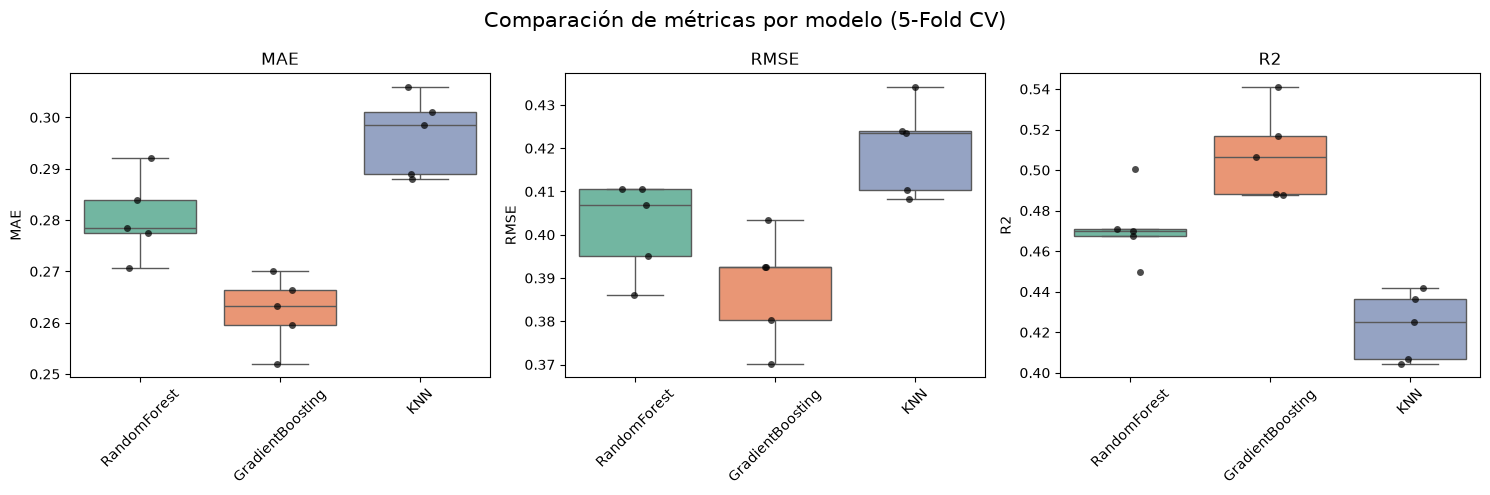

In [82]:
# Unificamos resultados en un solo dataframe
filas = []

for modelo, res in resultados.items():
    df = res["metricas"].copy().reset_index()   # recupera Fold como columna
    df["Modelo"] = modelo
    filas.append(df)

df_comparativo = pd.concat(filas, ignore_index=True)

metricas = ["MAE", "RMSE", "R2"]

modelos = df_comparativo["Modelo"].unique()

# Un color fijo por modelo
palette = dict(zip(modelos, sns.color_palette("Set2", n_colors=len(modelos))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metrica in zip(axes, metricas):

    sns.boxplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        hue="Modelo",
        order=modelos,
        hue_order=modelos,
        palette=palette,
        dodge=False,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        order=modelos,
        color="black",
        alpha=0.7,
        jitter=True,
        size=5,
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Comparación de métricas por modelo (5-Fold CV)", fontsize=15)
plt.tight_layout()
plt.show()

A partir de los boxplots obtenidos mediante validación cruzada de 5 folds, se observa que los tres modelos presentan una variabilidad relativamente acotada en sus métricas, lo que sugiere un comportamiento razonablemente consistente entre las distintas particiones de los datos.

Gradient Boosting se destaca por obtener sistemáticamente los mejores resultados en MAE, RMSE y R², aunque presenta cierta variabilidad entre folds. Por su parte, Random Forest muestra resultados relativamente estables, pero con un rendimiento predictivo inferior, mientras que KNN presenta las peores métricas de manera consistente.

En conjunto, los resultados favorecen a Gradient Boosting por su mejor desempeño predictivo, aunque no necesariamente por presentar la menor dispersión entre folds.

In [95]:
metricas_ajuste = []

for nombre, resultado in resultados.items():

    modelo = resultado["best_estimator"]

    # Predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Métricas de validación cruzada
    metricas_cv = resultado["metricas"].mean()

    metricas_ajuste.append({
        "Modelo": nombre,
        "R² Train": r2_score(y_train, pred_train),
        "R² CV": metricas_cv["R2"],
        "R² Test": r2_score(y_test, pred_test),
        "RMSE Train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE CV": metricas_cv["RMSE"],
        "RMSE Test": np.sqrt(mean_squared_error(y_test, pred_test))
    })

df_ajuste = pd.DataFrame(metricas_ajuste).set_index("Modelo")

# Diferencia entre entrenamiento y validación
df_ajuste["Diferencia R²"] = (
    df_ajuste["R² Train"] - df_ajuste["R² CV"]
)

display(df_ajuste.round(4))

,R² Train,R² CV,R² Test,RMSE Train,RMSE CV,RMSE Test,Diferencia R²
Modelo,,,,,,,
RandomForest,0.6695,0.4718,0.4828,0.3180,0.4019,0.3916,0.1977
GradientBoosting,0.6765,0.5081,0.5256,0.3146,0.3878,0.3750,0.1685
KNN,1.0000,0.4230,0.4260,0.0000,0.4201,0.4125,0.5770


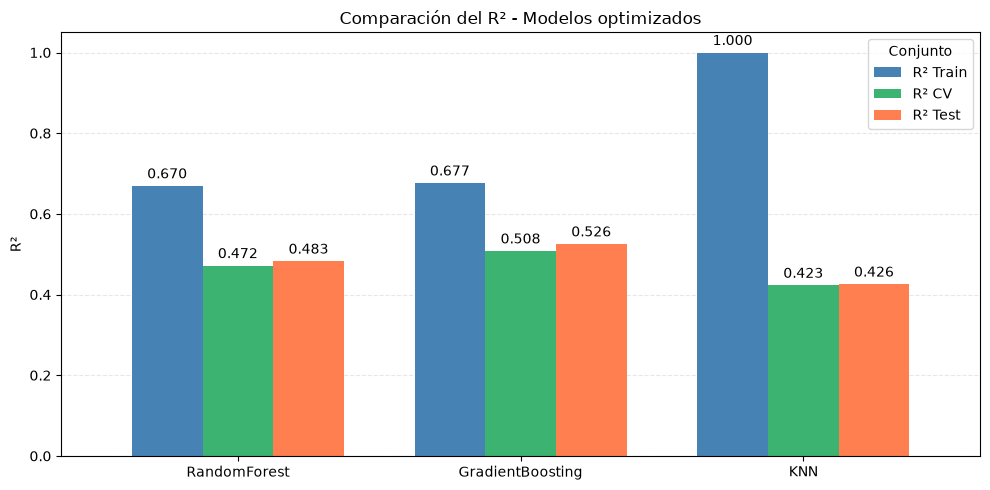

In [96]:
ax = df_ajuste[
    ["R² Train", "R² CV", "R² Test"]
].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.75,
    color=["steelblue", "mediumseagreen", "coral"]
)

ax.set_title("Comparación del R² - Modelos optimizados")
ax.set_xlabel("")
ax.set_ylabel("R²")
ax.set_ylim(
    min(0, df_ajuste[["R² Train", "R² CV", "R² Test"]].min().min() - 0.05),
    max(1, df_ajuste[["R² Train", "R² CV", "R² Test"]].max().max() + 0.05)
)
ax.legend(title="Conjunto")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

Comparamos con los modelos en default

In [100]:
nombres = [
    "Random Forest",
    "Gradient Boosting",
    "KNN"
]

comparacion = []

for nombre, fila in df_ajuste.iterrows():

    r2_train_default = df_default.loc[
        (nombre, "Train"), "R2"
    ]

    r2_test_default = df_default.loc[
        (nombre, "Test"), "R2"
    ]

    comparacion.append({
        "Modelo": nombre,
        "Brecha Default": r2_train_default - r2_test_default,
        "Brecha Optimizado": fila["R² Train"] - fila["R² Test"],
        "R² Test Default": r2_test_default,
        "R² Test Optimizado": fila["R² Test"]
    })

df_comparacion_ajuste = pd.DataFrame(comparacion).set_index("Modelo")

display(df_comparacion_ajuste.round(4))

,Brecha Default,Brecha Optimizado,R² Test Default,R² Test Optimizado
Modelo,,,,
RandomForest,0.4496,0.1867,0.4758,0.4828
GradientBoosting,0.0526,0.1509,0.4926,0.5256
KNN,0.2372,0.5740,0.3388,0.4260


### Análisis del sobreajuste después de la optimización

A partir de la comparación del R² entre entrenamiento, validación cruzada y prueba, se observan diferencias importantes en la capacidad de generalización de los modelos optimizados.

**Random Forest** presenta un sobreajuste moderado, con un R² de 0.670 en entrenamiento frente a 0.472 en validación cruzada y 0.483 en test. En comparación con el modelo inicial, la optimización permitió reducir considerablemente el sobreajuste, aunque la mejora predictiva fue pequeña.

**Gradient Boosting** muestra un comportamiento más equilibrado, alcanzando un R² de 0.677 en entrenamiento, 0.508 en validación cruzada y 0.526 en test. Si bien presenta ciertos indicios de sobreajuste, mantiene resultados relativamente consistentes entre validación y prueba, obteniendo el mejor desempeño predictivo de los tres modelos.

Por último, **KNN** presenta un sobreajuste considerable, con un R² perfecto de 1.000 en entrenamiento, pero de apenas 0.423 y 0.426 en validación cruzada y test, respectivamente. Esta diferencia indica que el modelo se ajusta excesivamente a las observaciones de entrenamiento, sin lograr generalizar ese rendimiento a datos nuevos.

En conclusión, **Gradient Boosting se mantiene como el modelo más adecuado**, al obtener las mejores métricas de validación cruzada y test, con un nivel de sobreajuste moderado. Random Forest consiguió controlar considerablemente su sobreajuste inicial, mientras que KNN continúa mostrando dificultades de generalización.